In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
raw_data = pd.read_csv(r'C:\Users\MAJEED\Desktop\APPS\data_jobs.csv')
raw_data.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


In [3]:
df = raw_data.copy()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   job_title_short        785741 non-null  object 
 1   job_title              785740 non-null  object 
 2   job_location           784696 non-null  object 
 3   job_via                785733 non-null  object 
 4   job_schedule_type      773074 non-null  object 
 5   job_work_from_home     785741 non-null  bool   
 6   search_location        785741 non-null  object 
 7   job_posted_date        785741 non-null  object 
 8   job_no_degree_mention  785741 non-null  bool   
 9   job_health_insurance   785741 non-null  bool   
 10  job_country            785692 non-null  object 
 11  salary_rate            33067 non-null   object 
 12  salary_year_avg        22003 non-null   float64
 13  salary_hour_avg        10662 non-null   float64
 14  company_name           785723 non-nu

In [5]:
df.isnull().sum()

job_title_short               0
job_title                     1
job_location               1045
job_via                       8
job_schedule_type         12667
job_work_from_home            0
search_location               0
job_posted_date               0
job_no_degree_mention         0
job_health_insurance          0
job_country                  49
salary_rate              752674
salary_year_avg          763738
salary_hour_avg          775079
company_name                 18
job_skills               117037
job_type_skills          117037
dtype: int64

In [6]:
#df[df['salary_year_avg'].notna()]

In [7]:
#df[(df['job_title_short'] == 'Data Analyst') & (df['salary_year_avg'].notna())]

In [8]:
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [9]:
df['job_posted_month'] = df['job_posted_date'].dt.month

In [10]:
df.columns

Index(['job_title_short', 'job_title', 'job_location', 'job_via',
       'job_schedule_type', 'job_work_from_home', 'search_location',
       'job_posted_date', 'job_no_degree_mention', 'job_health_insurance',
       'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg',
       'company_name', 'job_skills', 'job_type_skills', 'job_posted_month'],
      dtype='object')

In [11]:
#df.sort_values(by = 'job_posted_date', inplace = True)

In [12]:
#df.drop(['salary_hour_avg'], axis = 1, inplace = True)

In [13]:
#df.dropna(subset = ['salary_year_avg'], inplace = True)

In [14]:
#df.reset_index(drop=True, inplace=True)

In [15]:
df.groupby('job_title_short')['salary_year_avg'].min()

job_title_short
Business Analyst             16500.0
Cloud Engineer               42000.0
Data Analyst                 25000.0
Data Engineer                15000.0
Data Scientist               27000.0
Machine Learning Engineer    30000.0
Senior Data Analyst          30000.0
Senior Data Engineer         35000.0
Senior Data Scientist        45000.0
Software Engineer            28000.0
Name: salary_year_avg, dtype: float64

In [16]:
df.groupby('job_title_short')['salary_year_avg'].agg(['min', 'max', 'median'])

,min,max,median
job_title_short,,,
Business Analyst,16500.0,387460.0,85000.0
Cloud Engineer,42000.0,280000.0,90000.0
Data Analyst,25000.0,650000.0,90000.0
Data Engineer,15000.0,525000.0,125000.0
Data Scientist,27000.0,960000.0,127500.0
Machine Learning Engineer,30000.0,325000.0,106415.0
Senior Data Analyst,30000.0,425000.0,111175.0
Senior Data Engineer,35000.0,425000.0,147500.0
Senior Data Scientist,45000.0,890000.0,155500.0


In [17]:
df['salary_year_avg'].min()

15000.0

In [18]:
min_salary = df['salary_year_avg'].idxmin()

In [19]:
df.iloc[min_salary]

job_title_short                                              Data Engineer
job_title                                           Data Engineer - Hadoop
job_location                                                        Brazil
job_via                                                       via LinkedIn
job_schedule_type                                                Full-time
job_work_from_home                                                   False
search_location                                                     Brazil
job_posted_date                                        2023-12-09 10:05:30
job_no_degree_mention                                                 True
job_health_insurance                                                 False
job_country                                                         Brazil
salary_rate                                                           year
salary_year_avg                                                    15000.0
salary_hour_avg          

In [20]:
#df = df.drop_duplicates(subset = ['job_title', 'company_name'])
#df.reset_index(drop=True, inplace=True)
df.index.name = 'job_index'
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
job_index,,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN,6
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr...",1
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],...",10
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',...",7
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl...",8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"['bash', 'python', 'perl', 'linux', 'unix', 'k...","{'os': ['linux', 'unix'], 'other': ['kubernete...",3
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"['sas', 'sas', 'sql', 'excel']","{'analyst_tools': ['sas', 'excel'], 'programmi...",3
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"['powerpoint', 'excel']","{'analyst_tools': ['powerpoint', 'excel']}",3


In [21]:
top_countries = df['job_country'].value_counts().head(6).index
top_countries

Index(['United States', 'India', 'United Kingdom', 'France', 'Germany',
       'Spain'],
      dtype='object', name='job_country')

In [22]:
df_job_country_salary = df.pivot_table(index = 'job_country', values = 'salary_year_avg',
               columns = 'job_title_short', aggfunc = 'median')
df_job_country_salary = df_job_country_salary.loc[top_countries]
df_job = df_job_country_salary[['Data Analyst', 'Data Engineer', 'Data Scientist']]
df_job

job_title_short,Data Analyst,Data Engineer,Data Scientist
job_country,,,
United States,90000.0,125000.0,130000.0
India,100500.0,147500.0,114008.0
United Kingdom,87750.0,110000.0,105300.0
France,69175.0,98301.5,88128.0
Germany,103750.0,147500.0,131560.0
Spain,91977.0,133000.0,88128.0


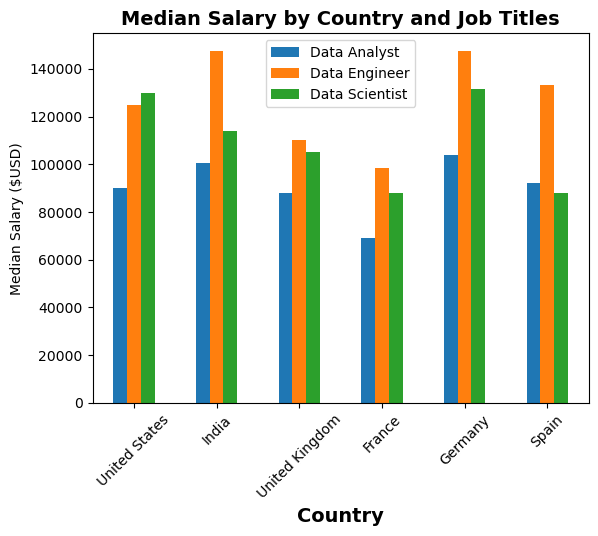

In [23]:
df_job.plot(kind = 'bar')
plt.xticks(rotation = 45)
plt.ylabel('Median Salary ($USD)')
plt.xlabel('Country', fontweight = 'bold', fontsize = 14)
plt.title('Median Salary by Country and Job Titles', fontsize = 14, fontweight = 'bold')

plt.legend()
plt.show()

In [24]:
df_job_title_salary = df.pivot_table(values = 'salary_year_avg', index = 'job_title_short', aggfunc = ['min', 'median', 'max'])
df_job_title_salary

,min,median,max
,salary_year_avg,salary_year_avg,salary_year_avg
job_title_short,,,
Business Analyst,16500.0,85000.0,387460.0
Cloud Engineer,42000.0,90000.0,280000.0
Data Analyst,25000.0,90000.0,650000.0
Data Engineer,15000.0,125000.0,525000.0
Data Scientist,27000.0,127500.0,960000.0
Machine Learning Engineer,30000.0,106415.0,325000.0
Senior Data Analyst,30000.0,111175.0,425000.0
Senior Data Engineer,35000.0,147500.0,425000.0


In [25]:
df_job_title_salary.sort_values(by = ('median', 'salary_year_avg'), ascending = False)

,min,median,max
,salary_year_avg,salary_year_avg,salary_year_avg
job_title_short,,,
Senior Data Scientist,45000.0,155500.0,890000.0
Senior Data Engineer,35000.0,147500.0,425000.0
Data Scientist,27000.0,127500.0,960000.0
Data Engineer,15000.0,125000.0,525000.0
Senior Data Analyst,30000.0,111175.0,425000.0
Machine Learning Engineer,30000.0,106415.0,325000.0
Software Engineer,28000.0,99150.0,375000.0
Cloud Engineer,42000.0,90000.0,280000.0


In [26]:
df_US = df[df['job_country'] == 'United States'].sort_values(by = 'job_posted_month')
df_US.reset_index(drop=True, inplace=True)
df_US.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
0,Data Analyst,Expert Business Data Analyst - Now Hiring,"Oakland, CA",via Snagajob,Full-time,False,"California, United States",2023-01-09 06:00:25,False,False,United States,NaN,NaN,NaN,PG&E Corporation,"['sql', 'python', 'tableau']","{'analyst_tools': ['tableau'], 'programming': ...",1
1,Data Analyst,Financial Data Analyst,"Dallas, TX",via LinkedIn,Full-time,False,"Texas, United States",2023-01-02 10:01:14,False,True,United States,NaN,NaN,NaN,Jobot,"['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['...",1
2,Senior Data Scientist,Sr. Imagery Data Scientist,United States,via Recruit.net,Full-time,False,"Texas, United States",2023-01-06 00:04:13,False,False,United States,NaN,NaN,NaN,RELX,"['azure', 'databricks', 'tensorflow', 'pytorch...","{'cloud': ['azure', 'databricks'], 'libraries'...",1
3,Data Scientist,Sr Data Scientist,"Irving, TX",via Dice,Contractor,False,"Texas, United States",2023-01-06 14:04:37,False,False,United States,NaN,NaN,NaN,Tech Rakers,"['python', 'sql', 'r', 'shell', 'aws', 'pyspar...","{'cloud': ['aws'], 'libraries': ['pyspark', 'h...",1
4,Data Scientist,Associate Data Scientist - Rainbow Babies & Ch...,"Cleveland, OH",via SimplyHired,Full-time,False,"Illinois, United States",2023-01-18 00:06:14,False,False,United States,NaN,NaN,NaN,University Hospitals,NaN,NaN,1


In [27]:
df_US['job_posted_monthly'] = df_US['job_posted_date'].dt.strftime('%B')
df_US.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month,job_posted_monthly
0,Data Analyst,Expert Business Data Analyst - Now Hiring,"Oakland, CA",via Snagajob,Full-time,False,"California, United States",2023-01-09 06:00:25,False,False,United States,NaN,NaN,NaN,PG&E Corporation,"['sql', 'python', 'tableau']","{'analyst_tools': ['tableau'], 'programming': ...",1,January
1,Data Analyst,Financial Data Analyst,"Dallas, TX",via LinkedIn,Full-time,False,"Texas, United States",2023-01-02 10:01:14,False,True,United States,NaN,NaN,NaN,Jobot,"['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['...",1,January
2,Senior Data Scientist,Sr. Imagery Data Scientist,United States,via Recruit.net,Full-time,False,"Texas, United States",2023-01-06 00:04:13,False,False,United States,NaN,NaN,NaN,RELX,"['azure', 'databricks', 'tensorflow', 'pytorch...","{'cloud': ['azure', 'databricks'], 'libraries'...",1,January
3,Data Scientist,Sr Data Scientist,"Irving, TX",via Dice,Contractor,False,"Texas, United States",2023-01-06 14:04:37,False,False,United States,NaN,NaN,NaN,Tech Rakers,"['python', 'sql', 'r', 'shell', 'aws', 'pyspar...","{'cloud': ['aws'], 'libraries': ['pyspark', 'h...",1,January
4,Data Scientist,Associate Data Scientist - Rainbow Babies & Ch...,"Cleveland, OH",via SimplyHired,Full-time,False,"Illinois, United States",2023-01-18 00:06:14,False,False,United States,NaN,NaN,NaN,University Hospitals,NaN,NaN,1,January


In [28]:
df_US_pivot = df_US.pivot_table(index = 'job_posted_monthly', columns = 'job_title_short', aggfunc = 'size')
df_US_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_monthly,,,,,,,,,,
April,565,40,6049,2801,4867,51,1025,781,991,112
August,903,39,6634,3269,6318,68,1186,903,1515,194
December,648,40,3979,2641,3472,119,601,689,752,212
February,447,24,6124,3060,4956,56,1258,878,1127,90
January,527,36,8494,2655,6915,60,1544,773,1552,114
July,581,39,5201,2570,4876,65,883,747,1095,153
June,446,32,5683,2893,4645,48,1009,812,1033,93
March,438,19,6218,3183,4779,59,1114,829,1150,115
May,279,20,4993,2976,4377,49,839,746,914,90


In [29]:
df_US_pivot['job_month'] = pd.to_datetime(df_US_pivot.index, format = '%B') # or '%b' for truncation) 
df_US_pivot['job_month'] = df_US_pivot['job_month'].dt.month
df_US_pivot.sort_values(by = 'job_month', inplace = True)
df_US_pivot.drop(['job_month'], axis = 1, inplace = True)

In [30]:
df_US_pivot.sum()

job_title_short
Business Analyst              7382
Cloud Engineer                 423
Data Analyst                 67816
Data Engineer                35080
Data Scientist               58830
Machine Learning Engineer      921
Senior Data Analyst          11791
Senior Data Engineer          9289
Senior Data Scientist        12946
Software Engineer             1814
dtype: int64

In [31]:
top_3 = df_US['job_title_short'].value_counts().head(3)
top_3.index.tolist()

['Data Analyst', 'Data Scientist', 'Data Engineer']

In [32]:
df_US_pivot = df_US_pivot[top_3.index.tolist()]
df_US_pivot

job_title_short,Data Analyst,Data Scientist,Data Engineer
job_posted_monthly,,,
January,8494,6915,2655
February,6124,4956,3060
March,6218,4779,3183
April,6049,4867,2801
May,4993,4377,2976
June,5683,4645,2893
July,5201,4876,2570
August,6634,6318,3269
September,4639,4568,3224


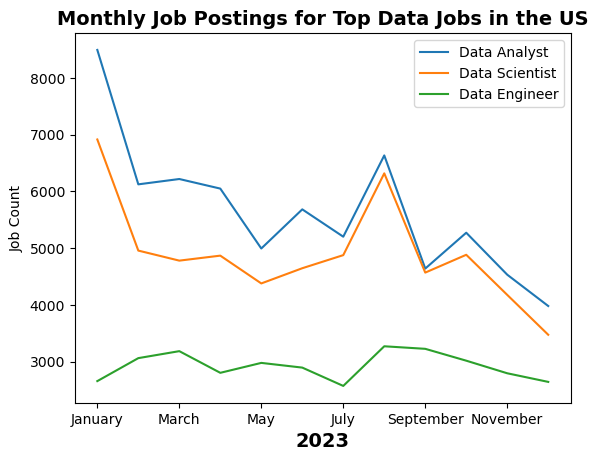

In [33]:
df_US_pivot.plot(kind = 'line')
plt.ylabel('Job Count')
plt.xlabel('2023', fontweight = 'bold', fontsize = 14)
plt.title('Monthly Job Postings for Top Data Jobs in the US', fontsize = 14, fontweight = 'bold')

plt.legend()
plt.show()

In [34]:
#to merge two datasets df_jobs and df_companies
#df_jobs.merge(df_companies, on = 'company_name')    company_name is the column common between the two datasets

In [35]:
#df.to_parquet('jobs_data.parquet')      to export/save file in parquet format(used when dealing with large dataset)

#df.to_pickel('jobs_data.pkl')      to export/save file in pickel format(also used when dealing with large dataset)

In [36]:
df_new = df[df['salary_year_avg'].notna()]

In [37]:
def projected_salary(x):
    return x * 1.03

In [38]:
#df_new['salary_inflated'] = projected_salary(df_new['salary_year_avg'])

df_new['salary_inflated'] = df_new['salary_year_avg']
df_new['salary_inflated'] = df_new['salary_inflated'].apply(lambda salary: salary * 1.03)

In [39]:
df_new[['salary_year_avg', 'salary_inflated']].head(2)

,salary_year_avg,salary_inflated
job_index,,
28,109500.0,112785.0
77,140000.0,144200.0


In [40]:
def inflated_salary(row):
    if "Senior" in row['job_title_short']:
        return 1.05 * row['salary_year_avg']
    else:
        return 1.03 * row['salary_year_avg']

df_new['salary_year_inflated'] = df_new.apply(inflated_salary, axis = 1)

In [41]:
df_new[df_new['job_title_short'] == 'Senior Data Engineer'][['job_title_short', 'salary_year_avg', 'salary_inflated', 'salary_year_inflated']]

,job_title_short,salary_year_avg,salary_inflated,salary_year_inflated
job_index,,,,
495,Senior Data Engineer,168500.0,173555.0,176925.0
573,Senior Data Engineer,160000.0,164800.0,168000.0
657,Senior Data Engineer,165000.0,169950.0,173250.0
726,Senior Data Engineer,173500.0,178705.0,182175.0
733,Senior Data Engineer,160000.0,164800.0,168000.0
...,...,...,...,...
782562,Senior Data Engineer,182500.0,187975.0,191625.0
783761,Senior Data Engineer,130000.0,133900.0,136500.0
784364,Senior Data Engineer,147500.0,151925.0,154875.0


In [42]:
df_new.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month,salary_inflated,salary_year_inflated
job_index,,,,,,,,,,,,,,,,,,,,
28,Data Scientist,CRM Data Specialist,"San José Province, San José, Costa Rica",via Ai-Jobs.net,Full-time,False,Costa Rica,2023-08-01 13:37:57,False,False,Costa Rica,year,109500.0,NaN,Netskope,"['gdpr', 'excel']","{'analyst_tools': ['excel'], 'libraries': ['gd...",8,112785.00,112785.00
77,Data Engineer,Data Engineer,"Arlington, VA",via LinkedIn,Full-time,False,Sudan,2023-06-26 14:22:54,False,False,Sudan,year,140000.0,NaN,Intelletec,"['mongodb', 'mongodb', 'python', 'r', 'sql', '...","{'analyst_tools': ['tableau'], 'cloud': ['orac...",6,144200.00,144200.00
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"['sql', 'python']","{'programming': ['sql', 'python']}",2,123600.00,123600.00
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"['sql', 'r', 'python', 'express']","{'programming': ['sql', 'r', 'python'], 'webfr...",7,235068.66,235068.66
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"['python', 'r', 'alteryx', 'tableau']","{'analyst_tools': ['alteryx', 'tableau'], 'pro...",10,91670.00,91670.00


In [43]:
df_new_2 = df[df['job_skills'].notna()]

In [44]:
import ast 

ast.literal_eval(df_new_2['job_skills'][1])

['r', 'python', 'sql', 'nosql', 'power bi', 'tableau']

In [45]:
def clean_list(skill_clean):
    return ast.literal_eval(skill_clean)

In [46]:
df_new_2['job_skills'] = df_new_2['job_skills'].apply(clean_list)

In [47]:
type(df_new['job_skills'][28])

str

In [48]:
type(df_new_2['job_skills'][1])

list

In [49]:
df_explode = df_new_2.explode('job_skills')
df_explode.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
job_index,,,,,,,,,,,,,,,,,,
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,r,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,python,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,sql,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,nosql,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,power bi,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1


<Axes: xlabel='job_skills'>

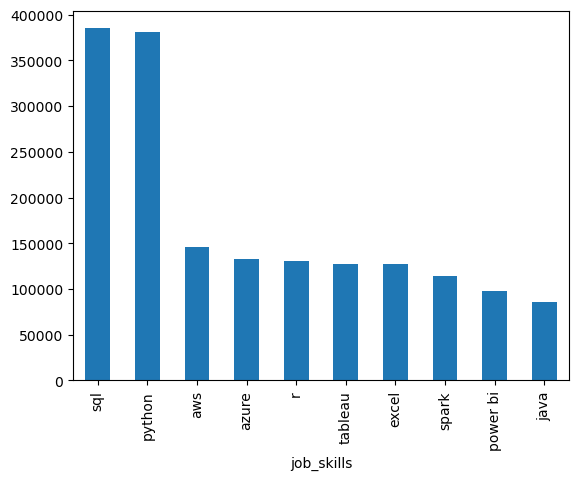

In [50]:
df_explode['job_skills'].value_counts().head(10).plot(kind = 'bar')

In [51]:
df_job_skills = df_explode[df_explode['job_title_short'] == 'Data Analyst']
df_job_skills = df_job_skills.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')).sort_values(by = 'skill_count', ascending = False).head(15)
df_job_skills

,skill_count,median_salary
job_skills,,
sql,92428,92500.0
excel,66860,84479.0
python,57190,98500.0
tableau,46455,95000.0
power bi,39380,90000.0
r,29996,92527.5
sas,27998,90000.0
powerpoint,13822,85000.0
word,13562,80000.0


In [52]:
#from adjustText import adjust_text

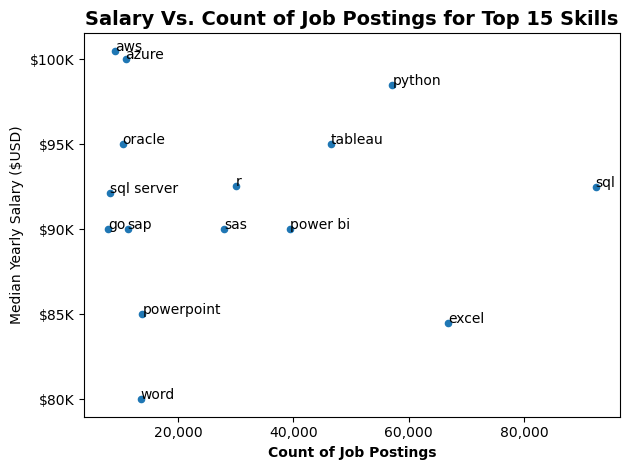

In [53]:
df_job_skills.plot(kind = 'scatter', x = 'skill_count', y = 'median_salary')

for i, txt in enumerate(df_job_skills.index):
    plt.text(df_job_skills['skill_count'].iloc[i], df_job_skills['median_salary'].iloc[i], txt)
    
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x):,}'))

plt.xlabel('Count of Job Postings', fontweight = 'bold')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Salary Vs. Count of Job Postings for Top 15 Skills', fontsize = 14, fontweight = 'bold')
    
plt.tight_layout()
plt.show()

In [54]:
skills_count = df_explode.groupby(['job_title_short', 'job_skills']).size()
type(skills_count)

pandas.core.series.Series

In [55]:
df_skills_count = skills_count.reset_index(name = 'skill_count')
df_skills_count = df_skills_count.sort_values(by = 'skill_count', ascending = False) 
df_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
266,Cloud Engineer,delphi,1
1920,Senior Data Scientist,objective-c,1
1400,Senior Data Analyst,couchdb,1
298,Cloud Engineer,haskell,1


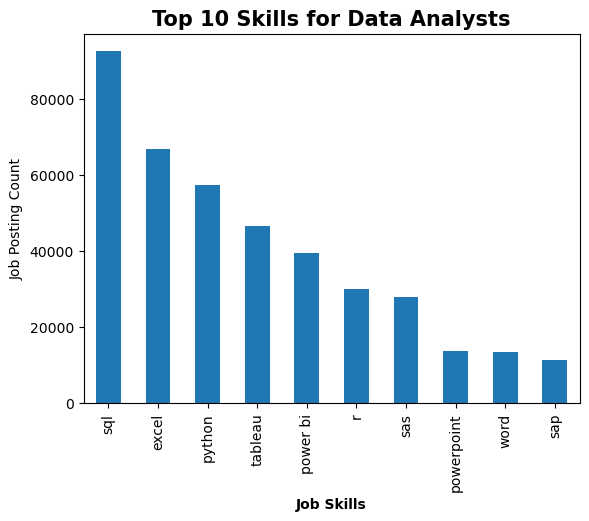

In [56]:
job_t = 'Data Analyst'
top_skills = 10

df_skills_final = df_skills_count[df_skills_count['job_title_short'] == job_t].head(top_skills)
df_skills_final.plot(kind = 'bar', x = 'job_skills', y = 'skill_count')
plt.xlabel('Job Skills', fontweight = 'bold')
plt.ylabel('Job Posting Count')
plt.legend().set_visible(False)
plt.title(f'Top {top_skills} Skills for {job_t}s', fontsize = 15, fontweight = 'bold')
plt.show()

In [57]:
job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer']

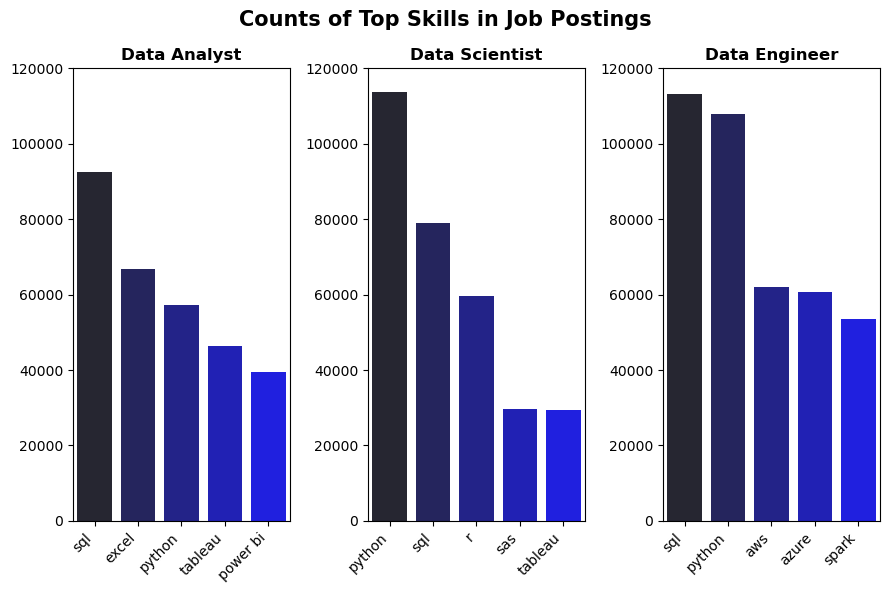

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(9, 6))

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    sns.barplot(data=df_plot, x='job_skills', y='skill_count', ax=ax[i], palette='dark:b')
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].set_ylim(0, 120000)
    ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')
    ax[i].set_title(job_title, fontsize=12, fontweight='bold')

plt.suptitle('Counts of Top Skills in Job Postings', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


In [59]:
df_explode['job_month'] = df_explode['job_posted_date'].dt.strftime('%b')
df_explode

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month,job_month
job_index,,,,,,,,,,,,,,,,,,,
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,r,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1,Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,python,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1,Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,sql,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1,Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,nosql,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1,Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,power bi,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",1,Jan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kafka,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh...",3,Mar
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kubernetes,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh...",3,Mar
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,docker,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh...",3,Mar


In [60]:
df_DA = df_explode[df_explode['job_title_short'] == 'Data Analyst']

In [61]:
skills_pivot_DA = df_DA.pivot_table(columns = 'job_skills', index =  'job_month', aggfunc = 'size', fill_value = 0)

In [62]:
skills_pivot_DA['job_m'] = pd.to_datetime(skills_pivot_DA.index, format = '%b')
skills_pivot_DA['job_m'] = skills_pivot_DA['job_m'].dt.month
skills_pivot_DA.sort_values(by = 'job_m', inplace = True)
skills_pivot_DA.drop(['job_m'], axis = 1, inplace = True)

In [63]:
#skills_pivot_DA.loc['Total'] = skills_pivot_DA.sum()   to get the total for each skill(at the row level)
#skills_pivot_DA[skills_pivot_DA.loc['Total'].sort_values(ascending = False).index] to sort ttl no of skills in descending order
skills_pivot_DA

job_skills,airflow,airtable,alteryx,angular,angular.js,ansible,apl,arch,asana,asp.net,...,webex,windows,wire,word,workfront,wrike,wsl,xamarin,yarn,zoom
job_month,,,,,,,,,,,,,,,,,,,,,
Jan,197,17,551,63,2,20,2,1,29,34,...,17,228,6,1778,0,11,6,0,9,95
Feb,169,2,448,49,0,14,1,4,27,13,...,9,202,6,1235,4,2,5,0,4,41
Mar,181,4,442,34,0,23,6,1,17,13,...,8,194,8,1203,1,1,3,1,5,45
Apr,155,4,413,22,0,11,8,9,9,15,...,9,185,14,1177,8,2,1,0,6,26
May,128,8,310,30,0,19,9,2,8,21,...,11,122,3,957,3,4,0,0,7,18
Jun,164,14,393,29,0,14,9,4,16,16,...,8,157,14,1237,6,6,0,0,11,34
Jul,207,4,366,15,0,8,5,8,19,12,...,5,161,11,1069,0,3,0,0,6,38
Aug,197,3,413,21,0,12,10,3,13,12,...,9,184,11,1298,0,1,0,0,11,41
Sep,118,4,317,21,0,14,3,10,12,10,...,4,150,8,945,0,1,0,0,5,25


In [64]:
top_skill = skills_pivot_DA.sum().sort_values(ascending = False).head()
top_skill = top_skill.index.tolist()
skills_pivot_DA = skills_pivot_DA[top_skill]

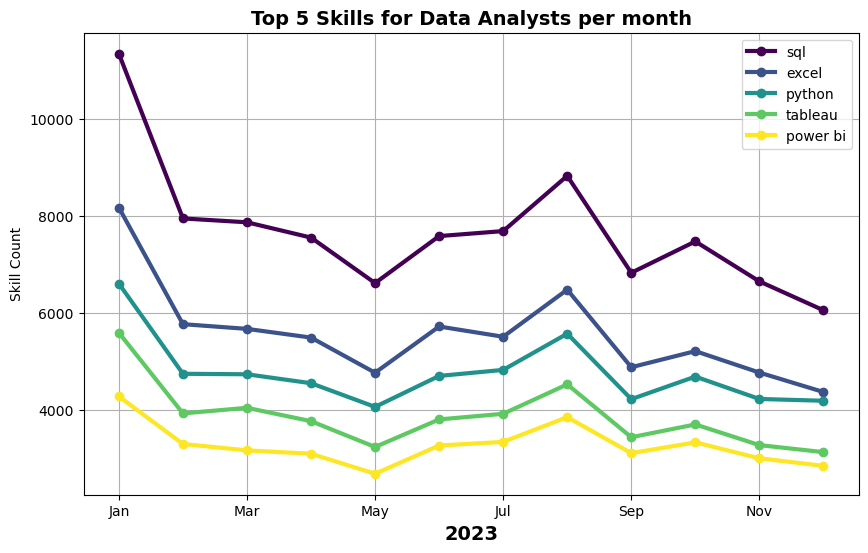

In [65]:
skills_pivot_DA.plot(kind = 'line', linewidth = 3,
                     #linestyle = ':',
                     colormap = 'viridis',
                     marker = 'o',
                     figsize = (10,6))
plt.ylabel('Skill Count')
plt.xlabel('2023', fontweight = 'bold', fontsize = 14)
plt.title('Top 5 Skills for Data Analysts per month', fontsize = 14, fontweight = 'bold')
plt.grid(True)

plt.legend()
plt.show()

In [66]:
skills_pivot = df_explode.pivot_table(columns = 'job_skills', index =  'job_month', aggfunc = 'size')

In [67]:
skills_pivot['job_m'] = pd.to_datetime(skills_pivot.index, format = '%b')
skills_pivot['job_m'] = skills_pivot['job_m'].dt.month
skills_pivot.sort_values(by = 'job_m', inplace = True)
skills_pivot.drop(['job_m'], axis = 1, inplace = True)

In [68]:
top_skills = skills_pivot.sum().sort_values(ascending = False).head()
top_skills = top_skills.index.tolist()

In [69]:
skills_pivot = skills_pivot[top_skills]

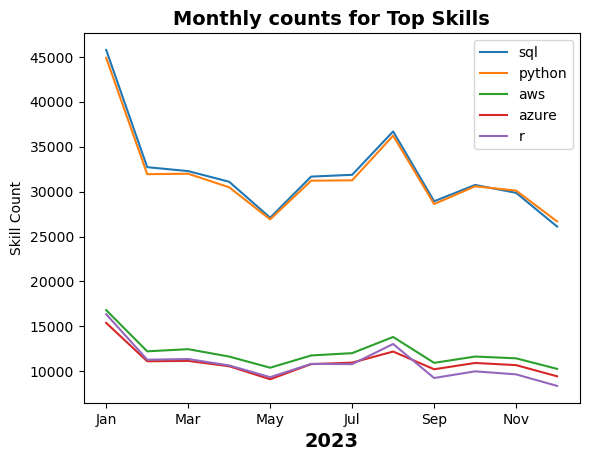

In [70]:
skills_pivot.plot(kind = 'line')
plt.ylabel('Skill Count')
plt.xlabel('2023', fontweight = 'bold', fontsize = 14)
plt.title('Monthly counts for Top Skills', fontsize = 14, fontweight = 'bold')

plt.legend()
plt.show()

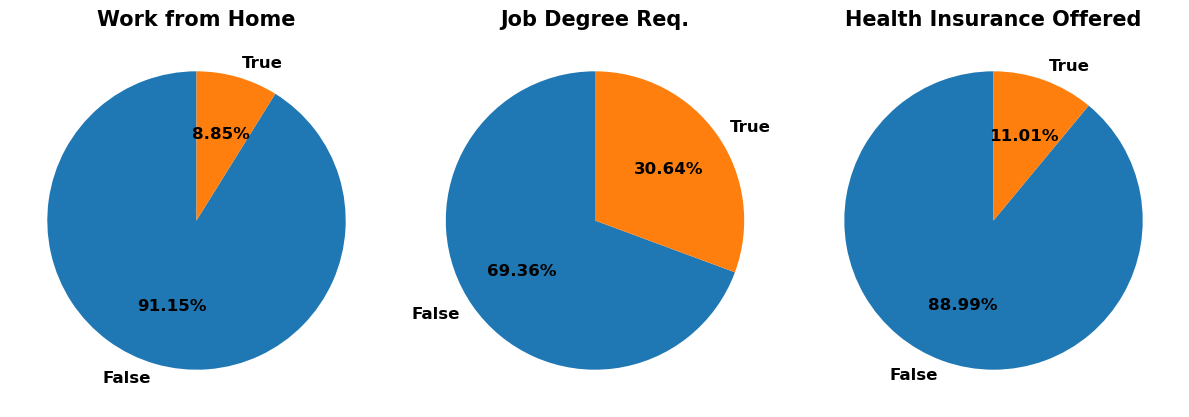

In [71]:
fig, ax = plt.subplots(1,3, figsize = (12,10))

dict_column = {'job_work_from_home': 'Work from Home',
              'job_no_degree_mention': 'Job Degree Req.',
              'job_health_insurance': 'Health Insurance Offered'}

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df[column].value_counts(),
        autopct = '%.2f%%',
        startangle = 90,
        labels = ['False', 'True'],
        textprops = {'size': 'large',
                   'fontweight': 'bold'})
    ax[i].set_title(title, fontsize = 15, fontweight = 'bold')
    
plt.tight_layout()
plt.show()

In [72]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]
df_DA_US 

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
job_index,,,,,,,,,,,,,,,,,,
36,Data Analyst,Data Analyst,"Des Moines, IA",via Trabajo.org,Full-time,False,"Illinois, United States",2023-11-06 13:01:22,False,True,United States,NaN,NaN,NaN,Assuredpartners,NaN,NaN,11
68,Data Analyst,Sr. Research Data Analyst,"Baltimore, MD",via ZipRecruiter,Full-time,False,"New York, United States",2023-03-24 13:01:00,False,False,United States,NaN,NaN,NaN,Johns Hopkins Medicine,"['r', 'zoom']","{'programming': ['r'], 'sync': ['zoom']}",3
73,Data Analyst,Entry level / Systems Data Analyst (Remote),Anywhere,via LinkedIn,Contractor,True,"Illinois, United States",2023-06-16 13:18:22,True,True,United States,NaN,NaN,NaN,Soft Magic,"['word', 'excel', 'powerpoint', 'outlook']","{'analyst_tools': ['word', 'excel', 'powerpoin...",6
79,Data Analyst,Data Analyst/Report Writer,"Austin, TX",via Jobs Trabajo.org,Full-time,False,"Texas, United States",2023-08-07 13:18:27,True,False,United States,NaN,NaN,NaN,Nesco Resource,"['sas', 'sas', 'word', 'excel']","{'analyst_tools': ['sas', 'word', 'excel'], 'p...",8
93,Data Analyst,IT Finance / TBM Data Analyst - Remote | WFH,Anywhere,via LinkedIn,Full-time,True,"New York, United States",2023-06-10 13:00:05,False,False,United States,NaN,NaN,NaN,Get It Recruit - Information Technology,"['oracle', 'azure', 'power bi', 'excel', 'word...","{'analyst_tools': ['power bi', 'excel', 'word'...",6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785603,Data Analyst,Junior Data Analyst,"Santa Monica, CA",via Trabajo.org,Full-time,False,"California, United States",2023-09-12 06:00:50,False,False,United States,NaN,NaN,NaN,"Ramax Search, Inc.","['sql', 'vba', 'python', 'excel', 'flow']","{'analyst_tools': ['excel'], 'other': ['flow']...",9
785626,Data Analyst,Data Acquisition Associate,"Tarrytown, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-29 06:01:29,False,False,United States,NaN,NaN,NaN,Planet Group,['microsoft teams'],{'sync': ['microsoft teams']},10
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['...",7


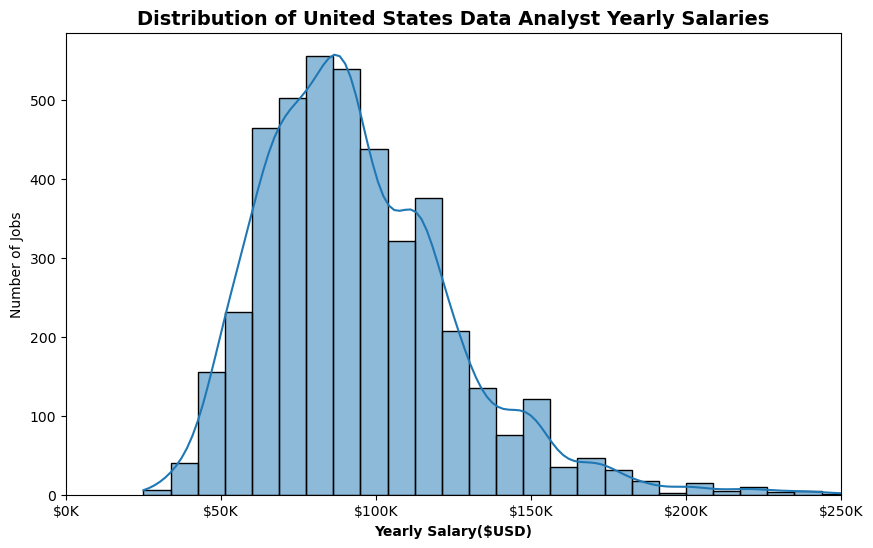

In [73]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=df_DA_US, x='salary_year_avg', kde=True, bins=40, edgecolor='black')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.xlim(0, 250000)
plt.title('Distribution of United States Data Analyst Yearly Salaries', fontsize=14, fontweight='bold')
plt.xlabel('Yearly Salary($USD)', fontweight='bold')
plt.ylabel('Number of Jobs')
plt.show()

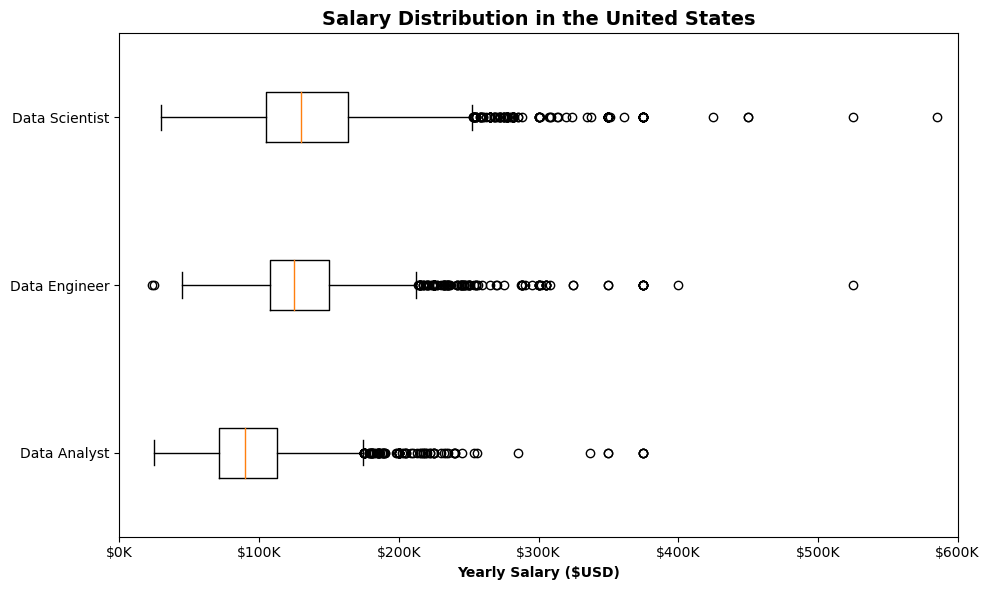

In [74]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')]
df_US.dropna(subset = ['salary_year_avg'], inplace = True)

job_list = [df_US[df_US['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

plt.figure(figsize = (10,6))
plt.boxplot(job_list, labels = job_titles, vert = False)
plt.title('Salary Distribution in the United States', fontsize = 14, fontweight = 'bold')
plt.xlabel('Yearly Salary ($USD)', fontweight = 'bold')
plt.xlim(0, 600000)

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.tight_layout()
plt.show()

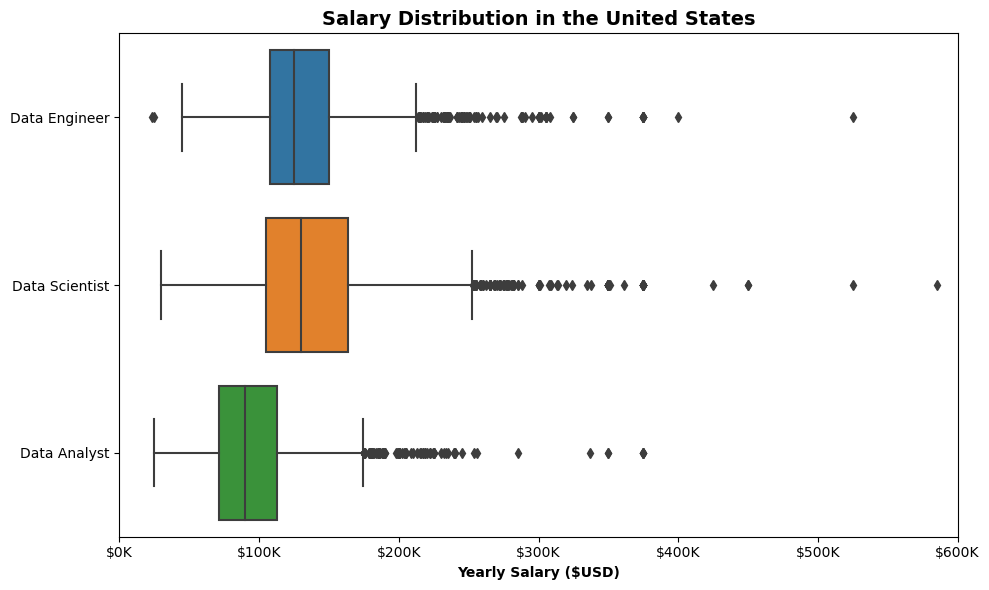

In [75]:
plt.figure(figsize = (10,6))
sns.boxplot(data = df_US, x = 'salary_year_avg', y = 'job_title_short')
plt.title('Salary Distribution in the United States', fontsize = 14, fontweight = 'bold')
plt.xlabel('Yearly Salary ($USD)', fontweight = 'bold')
plt.xlim(0, 600000)
plt.ylabel('')

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.tight_layout()
plt.show()

In [76]:
df_DA_exploded = df_explode[(df_explode['job_title_short'] == 'Data Analyst') & (df_explode['job_country'] == 'United States')]

In [77]:
df_DA_exploded = df_DA_exploded.dropna(subset = ['salary_year_avg'])

In [78]:
df_DA_grouped = df_DA_exploded.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])

In [79]:
df_DA_pay = df_DA_grouped.sort_values(by = 'median', ascending = False).head(10)
df_DA_pay

,count,median
job_skills,,
dplyr,2,196250.0
bitbucket,3,189000.0
gitlab,3,186000.0
solidity,1,179000.0
hugging face,1,175000.0
couchbase,1,160515.0
ansible,1,159640.0
mxnet,2,149000.0
cassandra,6,148250.0


In [80]:
df_DA_skills = df_DA_grouped.sort_values(by = 'count', ascending = False).head(10).sort_values(by = 'median', ascending = False).head(10)
df_DA_skills

,count,median
job_skills,,
python,1431,97500.00
tableau,1364,92875.00
r,893,92500.00
sql server,286,92500.00
sql,2508,91000.00
sas,926,90000.00
power bi,838,90000.00
powerpoint,462,85000.00
excel,1808,84392.00


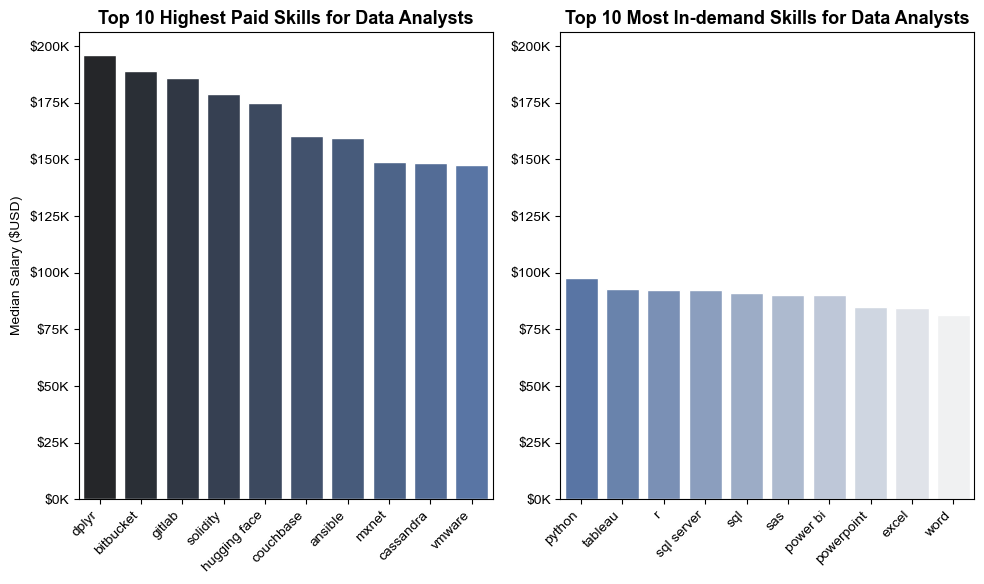

In [81]:
fig, ax = plt.subplots(1,2, figsize = (10,6))
sns.set_theme(style = 'ticks')

sns.barplot(data = df_DA_pay, y = 'median', x = df_DA_pay.index, ax = ax[0], palette = 'dark:b')
ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts', fontsize = 13, fontweight = 'bold')
ax[0].set_ylabel('Median Salary ($USD)')
ax[0].set_xlabel('')
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45, ha='right')
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))

sns.barplot(data = df_DA_skills, y = 'median', x = df_DA_skills.index, ax = ax[1], palette = 'light:b_r')
ax[1].set_title('Top 10 Most In-demand Skills for Data Analysts', fontsize = 13, fontweight = 'bold')
ax[1].set_ylabel('')
ax[1].set_xlabel('')
ax[1].set_ylim(ax[0].get_ylim())
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45, ha='right')
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))

plt.tight_layout()
plt.show()